In [4]:
import numpy as np
import pandas as pd
import pickle, json, warnings
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, f1_score, roc_curve
from scipy.stats import wilcoxon, ks_2samp
import shap
warnings.filterwarnings('ignore')

X_train = pd.read_parquet('acrs_data/X_train.parquet')
X_val   = pd.read_parquet('acrs_data/X_val.parquet')
X_test  = pd.read_parquet('acrs_data/X_test.parquet')
y_val   = np.load('acrs_data/y_val.npy')
y_test  = np.load('acrs_data/y_test.npy')

# Load models
with open('acrs_data/xgb_final.pkl',  'rb') as f: xgb_final  = pickle.load(f)
with open('acrs_data/lgbm_final.pkl', 'rb') as f: lgbm_final = pickle.load(f)
with open('acrs_data/rf_final.pkl',   'rb') as f: rf_final   = pickle.load(f)

# Load saved results from Layer 2 and 3
with open('acrs_data/layer2_results.json') as f: l2 = json.load(f)
with open('acrs_data/layer3_results.json') as f: l3 = json.load(f)

# Feature verification
assert X_test.shape[1] == 82, f"Expected 82 features, got {X_test.shape[1]}"


print(f"X_train: {X_train.shape} | X_val: {X_val.shape} | X_test: {X_test.shape}")
print("82 clean features confirmed")

X_train: (449858, 82) | X_val: (375220, 82) | X_test: (504194, 82)
82 clean features confirmed


In [6]:
# Test set predictions
prob_xgb_test  = xgb_final.predict_proba(X_test)[:,1]
prob_lgbm_test = lgbm_final.predict_proba(X_test)[:,1]
prob_rf_test   = rf_final.predict_proba(X_test)[:,1]
prob_ens_test  = (prob_xgb_test + prob_lgbm_test + prob_rf_test) / 3

# Val set predictions 
prob_xgb_val  = xgb_final.predict_proba(X_val)[:,1]
prob_lgbm_val = lgbm_final.predict_proba(X_val)[:,1]
prob_rf_val   = rf_final.predict_proba(X_val)[:,1]
prob_ens_val  = (prob_xgb_val + prob_lgbm_val + prob_rf_val) / 3

def get_metrics(y_true, y_prob):
    auc  = roc_auc_score(y_true, y_prob)
    ks   = ks_2samp(y_prob[y_true==1], y_prob[y_true==0]).statistic
    gini = 2 * auc - 1
    f1   = f1_score(y_true, (y_prob >= 0.5).astype(int))
    return auc, ks, gini, f1

print("Predictions ready for val and test sets")

Predictions ready for val and test sets


In [8]:
# Test set metrics
m_xgb  = get_metrics(y_test, prob_xgb_test)
m_lgbm = get_metrics(y_test, prob_lgbm_test)
m_rf   = get_metrics(y_test, prob_rf_test)
m_ens  = get_metrics(y_test, prob_ens_test)

# Wilcoxon: individual vs ensemble (10k sample)
np.random.seed(42)
idx = np.random.choice(len(y_test), 10000, replace=False)

err_xgb  = np.abs(prob_xgb_test  - y_test)
err_lgbm = np.abs(prob_lgbm_test - y_test)
err_rf   = np.abs(prob_rf_test   - y_test)
err_ens  = np.abs(prob_ens_test  - y_test)

_, p_xgb  = wilcoxon(err_xgb[idx],  err_ens[idx])
_, p_lgbm = wilcoxon(err_lgbm[idx], err_ens[idx])
_, p_rf   = wilcoxon(err_rf[idx],   err_ens[idx])

def sig(p): return "***" if p<0.001 else ("**" if p<0.01 else ("*" if p<0.05 else "ns"))

print("MODEL COMPARISON — TEST SET (2016+)")
print("=" * 75)
print(f"{'Model':<18} {'AUC':>7} {'KS':>7} {'Gini':>7} {'F1':>7}  {'Wilcoxon p':>13}  Sig")
print("=" * 75)
for name, m, p in [('XGBoost', m_xgb, p_xgb),
                   ('LightGBM', m_lgbm, p_lgbm),
                   ('RandomForest', m_rf, p_rf)]:
    print(f"{name:<18} {m[0]:>7.4f} {m[1]:>7.4f} {m[2]:>7.4f} {m[3]:>7.4f}  {p:>13.4e}  {sig(p)}")
print(f"{'Ensemble (L1-3)':<18} {m_ens[0]:>7.4f} {m_ens[1]:>7.4f} "
      f"{m_ens[2]:>7.4f} {m_ens[3]:>7.4f}  {'(baseline)':>13}  —")
print("=" * 75)
print("Sig: *** p<0.001  ** p<0.01  * p<0.05  ns = not significant")

MODEL COMPARISON — TEST SET (2016+)
Model                  AUC      KS    Gini      F1     Wilcoxon p  Sig
XGBoost             0.7071  0.2995  0.4142  0.0727    1.5964e-106  ***
LightGBM            0.7047  0.2962  0.4094  0.0611    9.1549e-102  ***
RandomForest        0.7008  0.2881  0.4015  0.0006    9.0837e-125  ***
Ensemble (L1-3)     0.7057  0.2974  0.4115  0.0345     (baseline)  —
Sig: *** p<0.001  ** p<0.01  * p<0.05  ns = not significant


In [14]:
# Both partitions on the SAME clean model
# This is the correct before/after comparison

print("ENSEMBLE PERFORMANCE — BOTH PARTITIONS")
print("=" * 60)
print(f"{'Metric':<20} {'Val (2015)':>15} {'Test (2016+)':>15}")
print("=" * 60)

m_ens_val  = get_metrics(y_val,  prob_ens_val)
m_ens_test = get_metrics(y_test, prob_ens_test)

for label, v, t in [('AUC-ROC',  m_ens_val[0], m_ens_test[0]),
                    ('KS Stat',  m_ens_val[1], m_ens_test[1]),
                    ('Gini',     m_ens_val[2], m_ens_test[2]),
                    ('F1 Score', m_ens_val[3], m_ens_test[3])]:
    print(f"{label:<20} {v:>15.4f} {t:>15.4f}")
print("=" * 60)
print("Note: Val = Optuna tuning partition. Test = held-out evaluation.")
print("All metrics computed on same clean 82-feature model.")

ENSEMBLE PERFORMANCE — BOTH PARTITIONS
Metric                    Val (2015)    Test (2016+)
AUC-ROC                       0.7427          0.7057
KS Stat                       0.3538          0.2974
Gini                          0.4853          0.4115
F1 Score                      0.0502          0.0345
Note: Val = Optuna tuning partition. Test = held-out evaluation.
All metrics computed on same clean 82-feature model.


In [16]:
print("3-LAYER ACRS FRAMEWORK COMPARISON")
print("=" * 65)
print(f"{'Capability':<30} {'Layer 1':>10} {'Layer 2':>10} {'Layer 3':>10}")
print("=" * 65)

rows = [
    ('AUC-ROC',         f"{m_ens[0]:.4f}", f"{l2['auc']:.4f}",  f"{l3['auc']:.4f}"),
    ('KS Statistic',    f"{m_ens[1]:.4f}", f"{l2['ks']:.4f}",   f"{l3['ks']:.4f}"),
    ('Gini Coefficient',f"{m_ens[2]:.4f}", f"{l2['gini']:.4f}", f"{l3['gini']:.4f}"),
    ('F1 Score',        f"{m_ens[3]:.4f}", f"{l2['f1']:.4f}",   f"{l3['f1']:.4f}"),
    ('PSI Monitoring',  '✗', f"{l2['psi_ensemble']:.4f}", f"{l3['psi_ensemble'] if 'psi_ensemble' in l3 else l2['psi_ensemble']:.4f}"),
    ('Drift Detection', '✗', '✗',  f"{l3['drift_alerts_5k']} alerts/5k"),
    ('Real-time SHAP',  '✗', 'Batch', 'Per-loan'),
    ('HITL Trigger',    '✗', '✗',  f"{l3['hitl_rate_pct']}%"),
    ('Audit Trail',     '✗', '✗',  '✓'),
]
for label, l1_val, l2_val, l3_val in rows:
    print(f"{label:<30} {l1_val:>10} {l2_val:>10} {l3_val:>10}")
print("=" * 65)

3-LAYER ACRS FRAMEWORK COMPARISON
Capability                        Layer 1    Layer 2    Layer 3
AUC-ROC                            0.7057     0.7057     0.7057
KS Statistic                       0.2974     0.2974     0.2974
Gini Coefficient                   0.4115     0.4115     0.4115
F1 Score                           0.0345     0.0345     0.0345
PSI Monitoring                          ✗     0.0038     0.0038
Drift Detection                         ✗          ✗ 10 alerts/5k
Real-time SHAP                          ✗      Batch   Per-loan
HITL Trigger                            ✗          ✗       3.1%
Audit Trail                             ✗          ✗          ✓


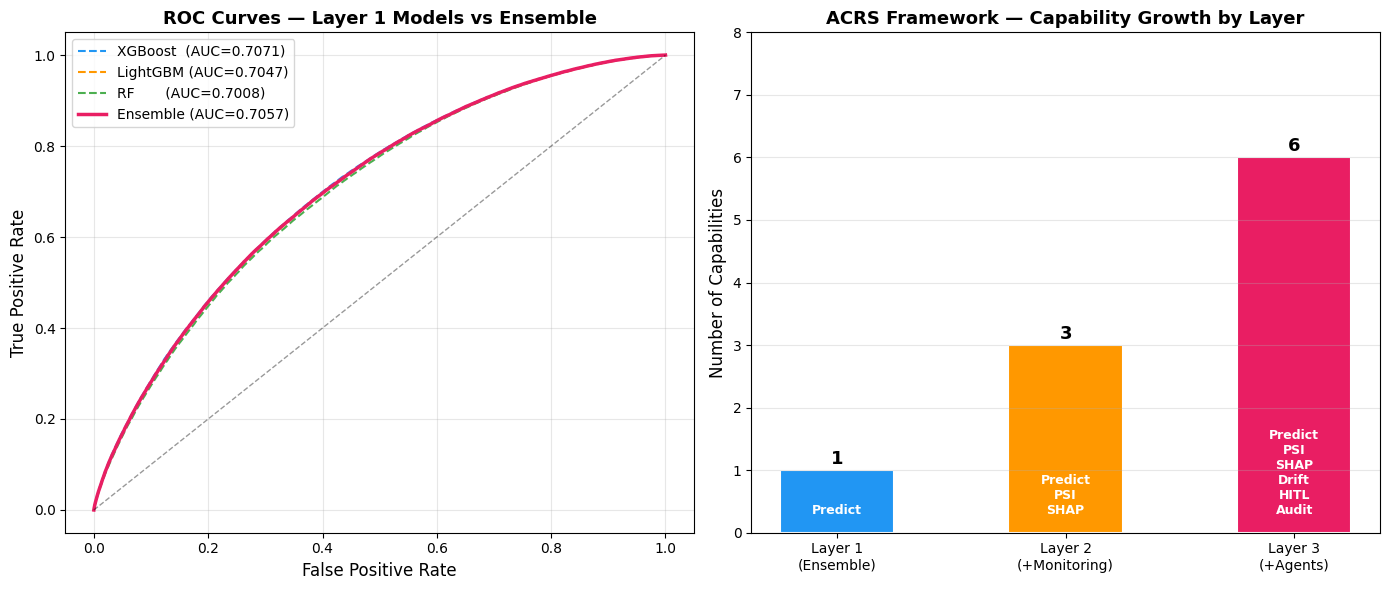

Saved: fig_roc_capability.png


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Left: ROC curves
ax = axes[0]
for prob, label, color in [
    (prob_xgb_test,  f'XGBoost  (AUC={m_xgb[0]:.4f})',  '#2196F3'),
    (prob_lgbm_test, f'LightGBM (AUC={m_lgbm[0]:.4f})', '#FF9800'),
    (prob_rf_test,   f'RF       (AUC={m_rf[0]:.4f})',    '#4CAF50'),
    (prob_ens_test,  f'Ensemble (AUC={m_ens[0]:.4f})',   '#E91E63'),
]:
    fpr, tpr, _ = roc_curve(y_test, prob)
    lw = 2.5 if 'Ensemble' in label else 1.5
    ls = '-' if 'Ensemble' in label else '--'
    ax.plot(fpr, tpr, label=label, linewidth=lw, linestyle=ls, color=color)

ax.plot([0,1],[0,1],'k--', alpha=0.4, linewidth=1)
ax.set_xlabel('False Positive Rate', fontsize=12)
ax.set_ylabel('True Positive Rate', fontsize=12)
ax.set_title('ROC Curves — Layer 1 Models vs Ensemble', fontsize=13, fontweight='bold')
ax.legend(fontsize=10); ax.grid(alpha=0.3)

# Right: Capability bar chart
ax2 = axes[1]
layers = ['Layer 1\n(Ensemble)', 'Layer 2\n(+Monitoring)', 'Layer 3\n(+Agents)']
capabilities = [1, 3, 6]
colors = ['#2196F3', '#FF9800', '#E91E63']
bars = ax2.bar(layers, capabilities, color=colors, width=0.5,
               edgecolor='white', linewidth=1.5)
ax2.set_ylabel('Number of Capabilities', fontsize=12)
ax2.set_title('ACRS Framework — Capability Growth by Layer',
              fontsize=13, fontweight='bold')
ax2.set_ylim(0, 8)
for bar, cap in zip(bars, capabilities):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.1,
             str(cap), ha='center', fontsize=13, fontweight='bold')
ax2.text(0, 0.3, 'Predict', ha='center', fontsize=9, color='white', fontweight='bold')
ax2.text(1, 0.3, 'Predict\nPSI\nSHAP', ha='center', fontsize=9, color='white', fontweight='bold')
ax2.text(2, 0.3, 'Predict\nPSI\nSHAP\nDrift\nHITL\nAudit', ha='center',
         fontsize=9, color='white', fontweight='bold')
ax2.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('acrs_data/fig_roc_capability.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: fig_roc_capability.png")

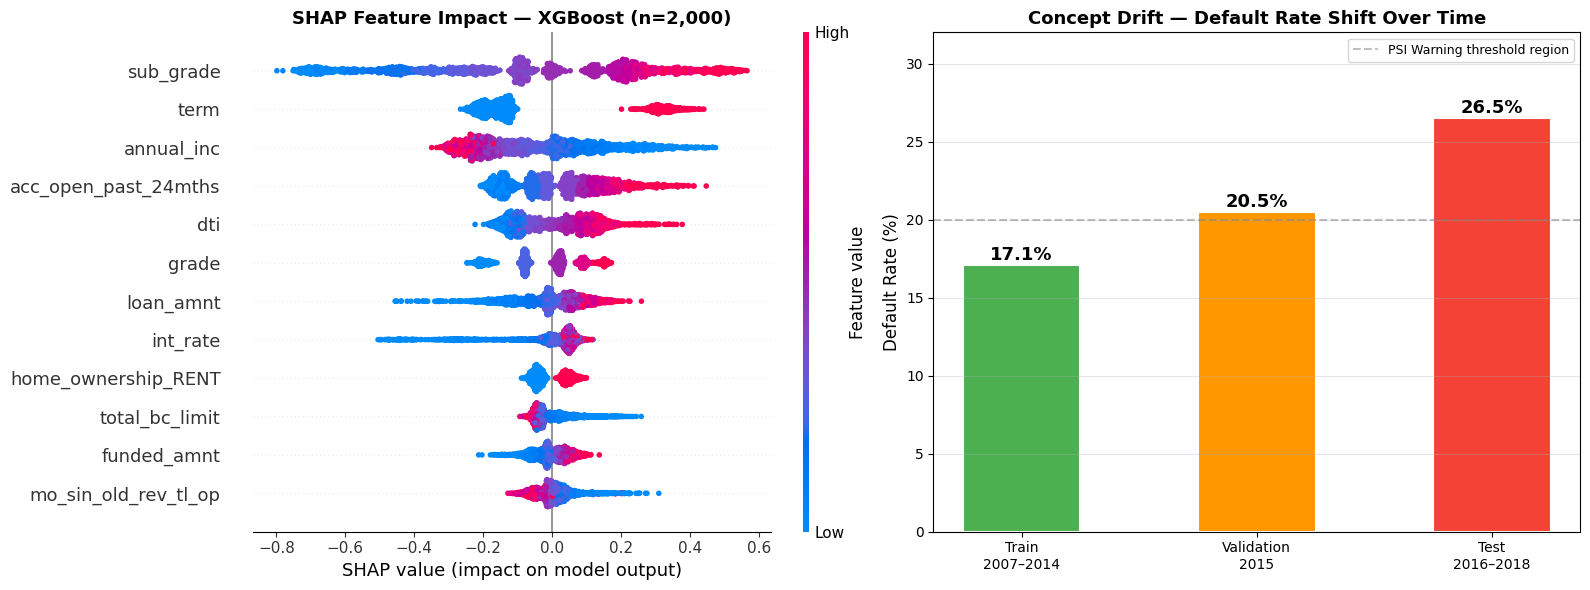

Saved: fig_shap_drift.png


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Left: SHAP beeswarm (from Layer 2 saved values)
shap_vals = np.load('acrs_data/shap_values_xgb_sample.npy')
X_shap    = X_test.iloc[np.random.RandomState(42).choice(len(X_test), 2000, replace=False)]

plt.sca(axes[0])
shap.summary_plot(shap_vals, X_shap, max_display=12, show=False, plot_size=None)
axes[0].set_title('SHAP Feature Impact — XGBoost (n=2,000)',
                  fontsize=13, fontweight='bold')

# Right: Default rate drift over time (actual data values)
ax3 = axes[1]
periods   = ['Train\n2007–2014', 'Validation\n2015', 'Test\n2016–2018']
def_rates = [17.1, 20.5, 26.5]
colors3   = ['#4CAF50', '#FF9800', '#F44336']
bars3 = ax3.bar(periods, def_rates, color=colors3, width=0.5,
                edgecolor='white', linewidth=1.5)
ax3.set_ylabel('Default Rate (%)', fontsize=12)
ax3.set_title('Concept Drift — Default Rate Shift Over Time',
              fontsize=13, fontweight='bold')
ax3.set_ylim(0, 32)
for bar, rate in zip(bars3, def_rates):
    ax3.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
             f'{rate}%', ha='center', fontsize=13, fontweight='bold')
ax3.axhline(y=20, color='gray', linestyle='--', alpha=0.5,
            label='PSI Warning threshold region')
ax3.grid(axis='y', alpha=0.3); ax3.legend(fontsize=9)

plt.tight_layout()
plt.savefig('acrs_data/fig_shap_drift.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: fig_shap_drift.png")

In [22]:
eval_results = {
    "xgb":  {"auc": round(m_xgb[0],4),  "ks": round(m_xgb[1],4),
              "gini": round(m_xgb[2],4), "f1": round(m_xgb[3],4),
              "wilcoxon_p": float(p_xgb),  "sig": sig(p_xgb)},
    "lgbm": {"auc": round(m_lgbm[0],4), "ks": round(m_lgbm[1],4),
              "gini": round(m_lgbm[2],4),"f1": round(m_lgbm[3],4),
              "wilcoxon_p": float(p_lgbm), "sig": sig(p_lgbm)},
    "rf":   {"auc": round(m_rf[0],4),   "ks": round(m_rf[1],4),
              "gini": round(m_rf[2],4),  "f1": round(m_rf[3],4),
              "wilcoxon_p": float(p_rf),   "sig": sig(p_rf)},
    "ensemble_test": {"auc": round(m_ens[0],4),     "ks": round(m_ens[1],4),
                      "gini": round(m_ens[2],4),    "f1": round(m_ens[3],4)},
    "ensemble_val":  {"auc": round(m_ens_val[0],4), "ks": round(m_ens_val[1],4),
                      "gini": round(m_ens_val[2],4),"f1": round(m_ens_val[3],4)},
}
with open('acrs_data/evaluation_results.json', 'w') as f:
    json.dump(eval_results, f, indent=2)

print("Saved: evaluation_results.json")
print("\nEVALUATION COMPLETE — All thesis figures and metrics saved")
print("Files: fig_roc_capability.png | fig_shap_drift.png | evaluation_results.json")

Saved: evaluation_results.json

EVALUATION COMPLETE — All thesis figures and metrics saved
Files: fig_roc_capability.png | fig_shap_drift.png | evaluation_results.json
